In [1]:
# ---------- CELL 1: imports and version check ----------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Draw charts inside the notebook, not in a separate window.
%matplotlib inline

# Print the versions, so we know everything is installed correctly.
# Better to find a problem NOW than 20 minutes into training.
print("pandas     :", pd.__version__)
print("numpy      :", np.__version__)

# Check PyTorch separately. It is the biggest library,
# and the most likely to be missing.
try:
    import torch
    print("torch      :", torch.__version__)
    print("Using CPU  :", not torch.cuda.is_available())
except ImportError:
    print("torch      : NOT INSTALLED")
    print("   Install it with:")
    print("   pip install torch --index-url https://download.pytorch.org/whl/cpu")

import sklearn
print("scikit-learn:", sklearn.__version__)

print()
print("Setup complete.")

pandas     : 3.0.6
numpy      : 2.5.3


torch      : 2.14.1+cpu
Using CPU  : True


scikit-learn: 1.9.1

Setup complete.


In [2]:
# ---------- CELL 2: load the dataset ----------

DATA_DIR = "data"
data = pd.read_csv(os.path.join(DATA_DIR, "training_data.csv"))

DATA_SOURCE = "GENERATED from Sri Lankan agronomic requirement values"

print("Rows     :", len(data))
print("Crops    :", data["crop"].nunique())
print("Features : soil_n, soil_p, soil_k, soil_ph, crop, stage, target_yield, zone")
print("Labels   : need_n, need_p, need_k")
print()
print(data.head())

Rows     : 3000
Crops    : 10
Features : soil_n, soil_p, soil_k, soil_ph, crop, stage, target_yield, zone
Labels   : need_n, need_p, need_k

   soil_n  soil_p  soil_k  soil_ph     crop       stage  target_yield zone  \
0    64.0    13.6    38.9     4.83   potato    seedling         13.13  wet   
1    50.1    12.2   213.3     7.09  coconut    maturity          8.49  dry   
2    64.0    11.1    77.3     5.66   potato    seedling         18.85  wet   
3    47.1     8.2    79.8     4.89     rice  vegetative          6.13  wet   
4    27.6    20.0   103.1     6.51   tomato  vegetative         20.67  dry   

   need_n  need_p  need_k  
0   12.66   10.09   16.97  
1    2.68    2.40    1.14  
2   18.89   13.37   24.31  
3   68.89   16.44   17.61  
4   50.30   20.37   29.70  


In [3]:
# ---------- CELL 3: look at the data ----------

print("=" * 55)
print("FIRST 5 ROWS")
print("=" * 55)
print(data.head())

print()
print("=" * 55)
print("SIZE")
print("=" * 55)
print("Rows    :", data.shape[0])
print("Columns :", data.shape[1])

print()
print("=" * 55)
print("COLUMN TYPES AND MISSING VALUES")
print("=" * 55)
data.info()

print()
print("=" * 55)
print("WHICH CROPS ARE IN THE DATA")
print("=" * 55)
# value_counts() counts how many rows each crop has.
print(data["crop"].value_counts())

FIRST 5 ROWS
   soil_n  soil_p  soil_k  soil_ph     crop       stage  target_yield zone  \
0    64.0    13.6    38.9     4.83   potato    seedling         13.13  wet   
1    50.1    12.2   213.3     7.09  coconut    maturity          8.49  dry   
2    64.0    11.1    77.3     5.66   potato    seedling         18.85  wet   
3    47.1     8.2    79.8     4.89     rice  vegetative          6.13  wet   
4    27.6    20.0   103.1     6.51   tomato  vegetative         20.67  dry   

   need_n  need_p  need_k  
0   12.66   10.09   16.97  
1    2.68    2.40    1.14  
2   18.89   13.37   24.31  
3   68.89   16.44   17.61  
4   50.30   20.37   29.70  

SIZE
Rows    : 3000
Columns : 11

COLUMN TYPES AND MISSING VALUES
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   soil_n        3000 non-null   float64
 1   soil_p        3000 non-null   float64
 2   soil_k    

In [4]:
# ---------- CELL 4: statistics ----------

print("=" * 70)
print("STATISTICS FOR EVERY NUMBER COLUMN")
print("=" * 70)

# .describe() gives count, mean, std, min, 25%, 50%, 75%, max
# .round(2) keeps it readable.
print(data.describe().round(2))

print()
print("=" * 70)
print("CHECKS")
print("=" * 70)

# CHECK 1: is any column completely flat?
# If std is 0, every value is the same, and the column is useless.
for col in data.select_dtypes(include=[np.number]).columns:
    std = data[col].std()
    if std < 0.0001:
        print(f"  PROBLEM: '{col}' never changes (std = {std}). It is useless.")
    else:
        print(f"  OK: '{col}' varies (std = {std:.2f})")

print()

# CHECK 2: are there impossible values?
# These are the same rules we built in Phase 4.
problems = 0

if (data["soil_ph"] < 0).any() or (data["soil_ph"] > 14).any():
    print("  PROBLEM: some pH values are outside 0 to 14")
    problems += 1

for col in ["soil_n", "soil_p", "soil_k"]:
    if (data[col] < 0).any():
        print(f"  PROBLEM: some {col} values are negative")
        problems += 1

if problems == 0:
    print("  OK: no impossible values found")

STATISTICS FOR EVERY NUMBER COLUMN
        soil_n   soil_p   soil_k  soil_ph  target_yield   need_n   need_p  \
count  3000.00  3000.00  3000.00  3000.00       3000.00  3000.00  3000.00   
mean     44.29    12.78    97.50     6.38         14.09    31.04    10.96   
std      20.27     6.21    50.00     0.95         10.23    21.94     7.53   
min       2.00     1.00     5.00     3.80          1.17     0.00     1.28   
25%      29.80     8.20    61.18     5.70          4.64    14.58     5.25   
50%      42.90    12.70    92.30     6.39         12.54    25.56     8.98   
75%      57.20    17.00   130.40     7.09         21.42    41.55    14.72   
max     124.70    35.90   284.60     8.80         49.25   137.84    55.00   

        need_k  
count  3000.00  
mean     20.75  
std      26.95  
min       0.00  
25%       4.41  
50%      12.15  
75%      26.67  
max     195.04  

CHECKS
  OK: 'soil_n' varies (std = 20.27)
  OK: 'soil_p' varies (std = 6.21)
  OK: 'soil_k' varies (std = 50.00)
  O

In [5]:
# ---------- CELL 6: check the labels ----------

label_cols = ["need_n", "need_p", "need_k"]

print("=" * 70)
print("LABEL STATISTICS")
print("=" * 70)
print(data[label_cols].describe().round(2))

print()
print("=" * 70)
print("CHECKS")
print("=" * 70)

for col in label_cols:
    values = data[col]

    # How many rows are exactly zero?
    zero_count = (values == 0).sum()
    zero_percent = 100 * zero_count / len(values)

    print(f"\n{col}:")
    print(f"  range   : {values.min():.1f} to {values.max():.1f}")
    print(f"  average : {values.mean():.1f}")
    print(f"  spread  : {values.std():.1f}")
    print(f"  zeros   : {zero_count} rows ({zero_percent:.1f}%)")

    # ----- The important checks -----
    if values.std() < 0.01:
        print("  PROBLEM: this label never changes. Nothing to learn.")
    elif zero_percent > 80:
        print("  PROBLEM: over 80% are zero.")
        print("           The model will just learn to always predict 0.")
    elif zero_percent > 50:
        print("  WARNING: over half are zero. Watch this during training.")
    else:
        print("  OK: good variation to learn from.")

LABEL STATISTICS
        need_n   need_p   need_k
count  3000.00  3000.00  3000.00
mean     31.04    10.96    20.75
std      21.94     7.53    26.95
min       0.00     1.28     0.00
25%      14.58     5.25     4.41
50%      25.56     8.98    12.15
75%      41.55    14.72    26.67
max     137.84    55.00   195.04

CHECKS

need_n:
  range   : 0.0 to 137.8
  average : 31.0
  spread  : 21.9
  zeros   : 1 rows (0.0%)
  OK: good variation to learn from.

need_p:
  range   : 1.3 to 55.0
  average : 11.0
  spread  : 7.5
  zeros   : 0 rows (0.0%)
  OK: good variation to learn from.

need_k:
  range   : 0.0 to 195.0
  average : 20.7
  spread  : 27.0
  zeros   : 298 rows (9.9%)
  OK: good variation to learn from.


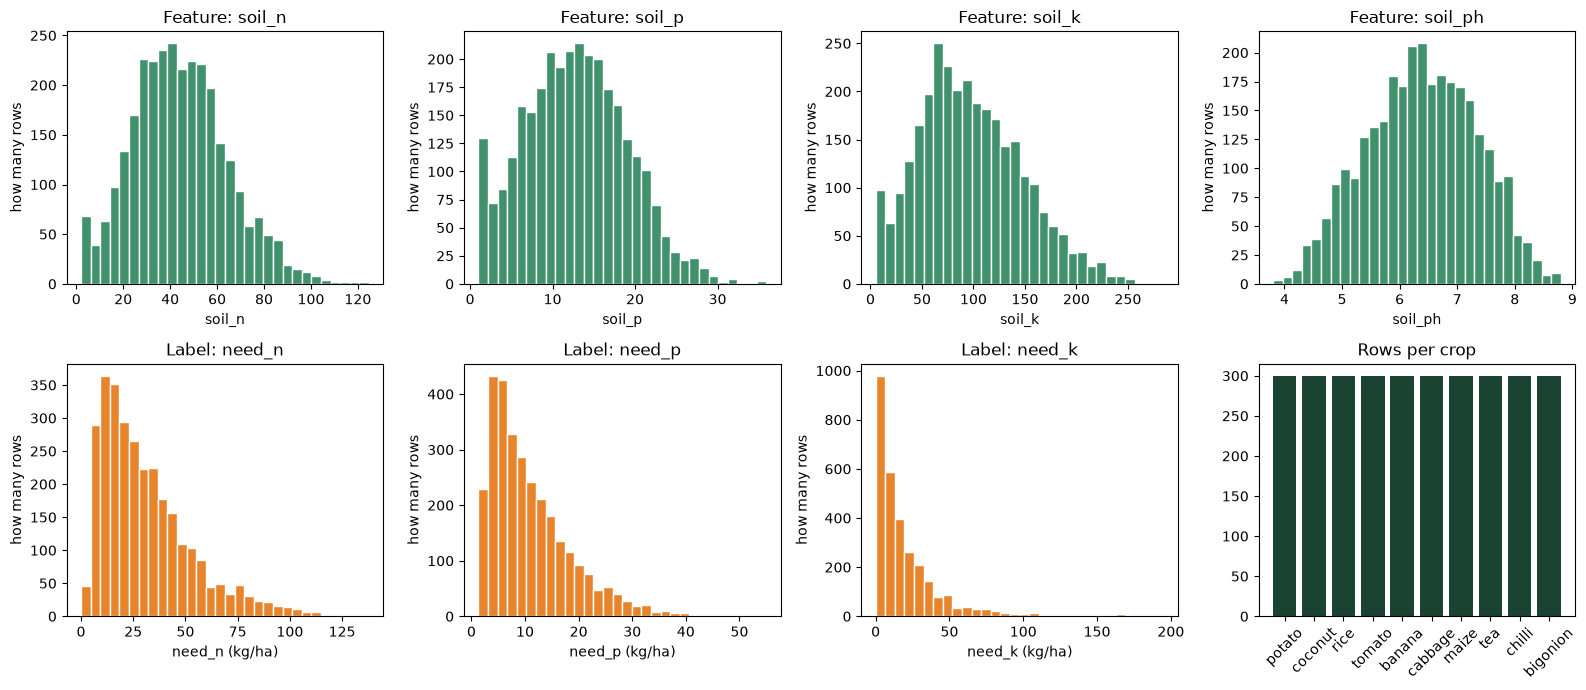


What to look for:
  GOOD : a hill shape, spread out
  BAD  : one tall bar at zero and nothing else
  BAD  : everything squeezed into one narrow spike


In [6]:
# ---------- CELL 7: draw charts ----------
#
# Numbers tell you facts. Charts show you the SHAPE.
# Your eyes find problems that numbers hide.

# One figure with 8 small charts. Easier on memory than 8 separate figures.
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

# ----- Top row: the FEATURES (what the model sees) -----
feature_cols = ["soil_n", "soil_p", "soil_k", "soil_ph"]

for i, col in enumerate(feature_cols):
    axes[0, i].hist(data[col], bins=30, color="#40916c", edgecolor="white")
    axes[0, i].set_title(f"Feature: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("how many rows")

# ----- Bottom row: the LABELS (what the model must predict) -----
for i, col in enumerate(label_cols):
    axes[1, i].hist(data[col], bins=30, color="#e8842c", edgecolor="white")
    axes[1, i].set_title(f"Label: {col}")
    axes[1, i].set_xlabel(col + " (kg/ha)")
    axes[1, i].set_ylabel("how many rows")

# ----- The last box: how many rows per crop -----
crop_counts = data["crop"].value_counts()
axes[1, 3].bar(crop_counts.index, crop_counts.values, color="#1b4332")
axes[1, 3].set_title("Rows per crop")
axes[1, 3].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Free the memory. Important on an 8GB laptop.
plt.close(fig)

print()
print("What to look for:")
print("  GOOD : a hill shape, spread out")
print("  BAD  : one tall bar at zero and nothing else")
print("  BAD  : everything squeezed into one narrow spike")

In [7]:
# ---------- CELL 8: clean and save ----------

rows_before = len(data)
print("Rows before cleaning:", rows_before)
print()

# ---------- STEP 1: remove rows with missing values ----------
# dropna() removes any row that has an empty value anywhere.
data_clean = data.dropna()
removed_missing = rows_before - len(data_clean)
print(f"Removed {removed_missing} rows with missing values")

# ---------- STEP 2: remove impossible values ----------
# These are the same rules as Phase 4.
before = len(data_clean)

data_clean = data_clean[
    (data_clean["soil_ph"] >= 0) & (data_clean["soil_ph"] <= 14) &
    (data_clean["soil_n"] >= 0) &
    (data_clean["soil_p"] >= 0) &
    (data_clean["soil_k"] >= 0) &
    (data_clean["target_yield"] > 0)
]

removed_impossible = before - len(data_clean)
print(f"Removed {removed_impossible} rows with impossible values")

# ---------- Report ----------
rows_after = len(data_clean)
percent_kept = 100 * rows_after / rows_before

print()
print("=" * 55)
print("CLEANING RESULT")
print("=" * 55)
print(f"Before : {rows_before}")
print(f"After  : {rows_after}")
print(f"Kept   : {percent_kept:.1f}%")

# NEVER remove data silently. Always check how much you lost.
if percent_kept < 90:
    print()
    print("WARNING: you removed more than 10% of the data.")
    print("         Go back and check what is wrong with it.")

# ---------- STEP 3: save it ----------
OUT_FILE = os.path.join(DATA_DIR, "training_data.csv")

# index=False stops Pandas adding an extra unnamed column.
data_clean.to_csv(OUT_FILE, index=False)

print()
print("Saved to:", OUT_FILE)
print("Part 2 will load this file. You do not need to rebuild it.")
print()
print("Data source was:", DATA_SOURCE)

Rows before cleaning: 3000

Removed 0 rows with missing values
Removed 0 rows with impossible values

CLEANING RESULT
Before : 3000
After  : 3000
Kept   : 100.0%

Saved to: data\training_data.csv
Part 2 will load this file. You do not need to rebuild it.

Data source was: GENERATED from Sri Lankan agronomic requirement values


In [8]:
# ---------- CELL 9: load and one-hot encode ----------

import pandas as pd
import numpy as np
import os

DATA_DIR = "data"
data = pd.read_csv(os.path.join(DATA_DIR, "training_data.csv"))

print("Loaded:", len(data), "rows")

# ---------- Separate features from labels ----------
FEATURE_RAW = ["soil_n", "soil_p", "soil_k", "soil_ph",
               "crop", "stage", "zone", "target_yield"]
LABEL_COLS = ["need_n", "need_p", "need_k"]

X = data[FEATURE_RAW].copy()
y = data[LABEL_COLS].copy()

print()
print("Before encoding:", X.shape[1], "columns")
print(X.head(3))

# ---------- ONE-HOT ENCODING ----------
#
# A neural network only does maths. It cannot understand "rice".
#
# WRONG way: rice=1, maize=2, tea=3
#   This creates a FAKE order. The model would think tea > rice.
#
# RIGHT way: give each crop its own column.
#   Put 1 in that column, 0 everywhere else. No fake order.

X = pd.get_dummies(X, columns=["crop", "stage", "zone"])

# get_dummies makes True/False. Convert to 1.0/0.0 for PyTorch.
X = X.astype(float)

print()
print("After encoding:", X.shape[1], "columns")
print()

# ---------- SAVE THE COLUMN ORDER ----------
#
# CRITICAL FOR PHASE 6.
#
# FastAPI must build its input array in EXACTLY this order.
# If the order differs, the model gets nitrogen where it expects pH,
# and gives wrong answers with NO error message.
FEATURE_COLUMNS = list(X.columns)

print("Column order (Phase 6 must match this exactly):")
for i, c in enumerate(FEATURE_COLUMNS):
    print(f"  {i:2d}. {c}")

Loaded: 3000 rows

Before encoding: 8 columns
   soil_n  soil_p  soil_k  soil_ph     crop     stage zone  target_yield
0    64.0    13.6    38.9     4.83   potato  seedling  wet         13.13
1    50.1    12.2   213.3     7.09  coconut  maturity  dry          8.49
2    64.0    11.1    77.3     5.66   potato  seedling  wet         18.85

After encoding: 22 columns

Column order (Phase 6 must match this exactly):
   0. soil_n
   1. soil_p
   2. soil_k
   3. soil_ph
   4. target_yield
   5. crop_banana
   6. crop_bigonion
   7. crop_cabbage
   8. crop_chilli
   9. crop_coconut
  10. crop_maize
  11. crop_potato
  12. crop_rice
  13. crop_tea
  14. crop_tomato
  15. stage_flowering
  16. stage_maturity
  17. stage_seedling
  18. stage_vegetative
  19. zone_dry
  20. zone_intermediate
  21. zone_wet


In [9]:
# ---------- CELL 10: train and test split ----------

from sklearn.model_selection import train_test_split

# Hide 20% of the data. The model NEVER sees it during training.
#
# Why? Because testing on data the model learned from tells you
# nothing. A student who memorised the practice answers scores
# 100% on those questions, and fails on new ones.
#
# random_state=42 makes the split the SAME every time,
# so your results are reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training set:", len(X_train), "rows  (the model learns from these)")
print("Test set    :", len(X_test), "rows  (HIDDEN until the very end)")
print()
print("Input columns :", X_train.shape[1])
print("Output columns:", y_train.shape[1])

Training set: 2400 rows  (the model learns from these)
Test set    : 600 rows  (HIDDEN until the very end)

Input columns : 22
Output columns: 3


In [10]:
# ---------- CELL 11: scaling ----------

from sklearn.preprocessing import MinMaxScaler
import joblib

ARTIFACTS_DIR = "../artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# ---------- Scale the FEATURES ----------
#
# WHY? Look at the ranges:
#   soil_ph  : 4 to 9
#   soil_k   : 5 to 320
#   is_rice  : 0 or 1
#
# soil_k has much BIGGER numbers. Without scaling it would
# DOMINATE the maths, and pH would be almost ignored,
# even if pH is more important.
#
# Min-Max scaling squeezes everything into 0 to 1.
#   scaled = (value - min) / (max - min)
feature_scaler = MinMaxScaler()

# CRITICAL RULE:
#   fit_transform on TRAIN  -> LEARN the min/max, then apply
#   transform     on TEST   -> ONLY apply. Do NOT learn.
#
# Fitting on all data would let training see the test set's
# min and max. That is DATA LEAKAGE, and your score would be a lie.
X_train_scaled = feature_scaler.fit_transform(X_train)
X_test_scaled = feature_scaler.transform(X_test)

# ---------- Scale the LABELS too ----------
#
# WHY? need_k goes up to 195, need_p only to 55.
# Without scaling, the model would focus on need_k,
# because its errors look bigger.
label_scaler = MinMaxScaler()
y_train_scaled = label_scaler.fit_transform(y_train)
y_test_scaled = label_scaler.transform(y_test)

# ---------- SAVE THEM ----------
#
# CRITICAL FOR PHASE 6.
#
# A farmer's new reading must be scaled EXACTLY the same way.
# With a different min/max, the model sees numbers in a range it
# never learned on, and gives WRONG answers with NO error message.
#
# Your project document calls this the SCALER-CONSISTENCY RULE.
joblib.dump(feature_scaler, os.path.join(ARTIFACTS_DIR, "feature_scaler.pkl"))
joblib.dump(label_scaler, os.path.join(ARTIFACTS_DIR, "label_scaler.pkl"))
joblib.dump(FEATURE_COLUMNS, os.path.join(ARTIFACTS_DIR, "feature_columns.pkl"))

print("Scaling done.")
print()
print("Before scaling, soil_k range:",
      round(X_train['soil_k'].min(), 1), "to", round(X_train['soil_k'].max(), 1))
print("After scaling, all features :",
      round(X_train_scaled.min(), 2), "to", round(X_train_scaled.max(), 2))
print()
print("Saved to", ARTIFACTS_DIR, ":")
print("  feature_scaler.pkl   (Phase 6 needs this)")
print("  label_scaler.pkl     (Phase 6 needs this)")
print("  feature_columns.pkl  (Phase 6 needs this)")

Scaling done.



Before scaling, soil_k range: 5.0 to 284.6
After scaling, all features : 0.0 to 1.0

Saved to ../artifacts :
  feature_scaler.pkl   (Phase 6 needs this)
  label_scaler.pkl     (Phase 6 needs this)
  feature_columns.pkl  (Phase 6 needs this)


In [11]:
# ---------- CELL 12: convert to PyTorch tensors ----------

import torch
from torch.utils.data import TensorDataset, DataLoader

# Make results reproducible.
torch.manual_seed(42)

# ---------- Convert to tensors ----------
#
# A TENSOR is PyTorch's array of numbers.
# It is like a NumPy array, but it can REMEMBER how it was
# calculated, which is what makes backpropagation possible.
#
# float32 uses HALF the memory of float64, and neural networks
# do not need the extra precision. Good for an 8GB laptop.
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test_scaled, dtype=torch.float32)

# ---------- Build a DataLoader ----------
#
# A DataLoader feeds the data in small groups called BATCHES.
#
# WHY batches?
#   1. MEMORY  - only one batch is in memory at a time
#   2. SPEED   - 2400 rows / 32 = 75 weight updates per epoch,
#                instead of just 1
#   3. ESCAPE  - the small randomness helps avoid getting stuck
#
# shuffle=True reorders the data every epoch, so the model
# learns the PATTERN, not the ORDER.
BATCH_SIZE = 32

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

print("Tensors ready.")
print()
print("X_train:", tuple(X_train_t.shape), " (rows, features)")
print("y_train:", tuple(y_train_t.shape), " (rows, labels)")
print()
print("Batch size   :", BATCH_SIZE)
print("Batches/epoch:", len(train_loader))

Tensors ready.

X_train: (2400, 22)  (rows, features)
y_train: (2400, 3)  (rows, labels)

Batch size   : 32
Batches/epoch: 75


In [12]:
# ---------- CELL 13: build the neural network ----------

import torch.nn as nn

INPUT_SIZE = X_train_t.shape[1]   # 22 features
OUTPUT_SIZE = y_train_t.shape[1]  # 3 labels

HIDDEN_1 = 64
HIDDEN_2 = 32
DROPOUT = 0.15


class FertilizerNet(nn.Module):
    """
    Predicts how much N, P and K a crop still needs.

    Shape:  22 features -> 64 -> 32 -> 3 numbers

    WHY TWO HIDDEN LAYERS?
      0 hidden  : only straight lines. Too simple.
      1-2 hidden: curves and interactions. Right for tabular data.
      5+ hidden : needs far more data, would overfit here.

    Our problem HAS interactions, like "low pH makes phosphorus
    less available". Two layers handle that well.
    """

    def __init__(self):
        super().__init__()

        # ----- HIDDEN LAYER 1 -----
        # Linear  : do the multiply-and-add
        # ReLU    : bend the line, so curves can be learned
        # Dropout : randomly switch off neurons, to stop memorising
        self.layer1 = nn.Linear(INPUT_SIZE, HIDDEN_1)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(DROPOUT)

        # ----- HIDDEN LAYER 2 -----
        self.layer2 = nn.Linear(HIDDEN_1, HIDDEN_2)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(DROPOUT)

        # ----- OUTPUT LAYER -----
        # NO activation here.
        # Our output is a NUMBER that can be anything.
        # ReLU would block negatives, and our scaled labels
        # can sit near zero.
        self.output = nn.Linear(HIDDEN_2, OUTPUT_SIZE)

    def forward(self, x):
        """PyTorch calls this automatically. Data flows top to bottom."""
        x = self.layer1(x)
        x = self.relu1(x)
        x = self.drop1(x)

        x = self.layer2(x)
        x = self.relu2(x)
        x = self.drop2(x)

        x = self.output(x)
        return x


model = FertilizerNet()

print(model)
print()

# A PARAMETER is one weight or one bias: one number the model learns.
total = sum(p.numel() for p in model.parameters())
print("Total parameters:", total)
print()
print("That is tiny. It will train in seconds on your CPU.")

FertilizerNet(
  (layer1): Linear(in_features=22, out_features=64, bias=True)
  (relu1): ReLU()
  (drop1): Dropout(p=0.15, inplace=False)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (relu2): ReLU()
  (drop2): Dropout(p=0.15, inplace=False)
  (output): Linear(in_features=32, out_features=3, bias=True)
)

Total parameters: 3651

That is tiny. It will train in seconds on your CPU.


In [13]:
# ---------- CELL 14: loss function and optimizer ----------

import torch.optim as optim

# ---------- LOSS FUNCTION ----------
#
# MSE = Mean Squared Error.
#   error = prediction - correct answer
#   square it, then average.
#
# WHY SQUARE?
#   1. It removes the minus sign. -5 is as bad as +5.
#   2. It punishes BIG mistakes hard.
#      An error of 20 gives 400. An error of 5 gives 25.
#      That is 16x more, from an error only 4x bigger.
#
# This is what we want. In fertilizer advice, being wrong by
# 50 kg is FAR worse than being wrong by 5 kg.
criterion = nn.MSELoss()

# ---------- OPTIMIZER ----------
#
# GRADIENT DESCENT in one picture:
#   You are on a foggy hill and want to reach the bottom.
#   You cannot see far, but you can feel the SLOPE.
#   So you take a small step downhill. Repeat.
#
#   the hill     = the loss
#   the slope    = the gradient (backpropagation finds it)
#   step size    = the learning rate
#
# ADAM is a smarter gradient descent. It adjusts the step size
# automatically for each weight. It just works, with little tuning.
LEARNING_RATE = 0.001

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

print("Loss function : MSE (Mean Squared Error)")
print("Optimizer     : Adam")
print("Learning rate :", LEARNING_RATE)
print()
print("Learning rate guide:")
print("  too big   (0.1)      -> overshoots, bounces around")
print("  good      (0.001)    -> steady progress down  <-- ours")
print("  too small (0.000001) -> gets there, but very slowly")

Loss function : MSE (Mean Squared Error)
Optimizer     : Adam
Learning rate : 0.001

Learning rate guide:
  too big   (0.1)      -> overshoots, bounces around
  good      (0.001)    -> steady progress down  <-- ours
  too small (0.000001) -> gets there, but very slowly


In [14]:
# ---------- CELL 15: train the model ----------

import copy
import time

EPOCHS = 300
PATIENCE = 30   # stop if the test loss does not improve for this many epochs

train_losses = []
test_losses = []

best_test_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

print("Training started...")
print()
start_time = time.time()

for epoch in range(EPOCHS):

    # ================= TRAINING =================
    model.train()   # dropout ON
    epoch_train_loss = 0.0

    for batch_X, batch_y in train_loader:

        # ---- THE FIVE STEPS. ALWAYS THESE FIVE. ----

        # STEP 1: clear the old gradients.
        # PyTorch ADDS UP gradients. If you forget this, gradients
        # from every previous batch pile up and training breaks.
        # THIS IS THE NUMBER ONE PYTORCH BEGINNER MISTAKE.
        optimizer.zero_grad()

        # STEP 2: forward pass. Make a prediction.
        predictions = model(batch_X)

        # STEP 3: measure how wrong it is.
        loss = criterion(predictions, batch_y)

        # STEP 4: backpropagation. Work out the slope for every weight.
        loss.backward()

        # STEP 5: take a small step downhill.
        optimizer.step()

        epoch_train_loss += loss.item()

    epoch_train_loss /= len(train_loader)

    # ================= TESTING =================
    model.eval()   # dropout OFF - all neurons active

    # no_grad() switches off gradient tracking.
    # Faster, and uses less memory. Good for an 8GB laptop.
    with torch.no_grad():
        test_pred = model(X_test_t)
        epoch_test_loss = criterion(test_pred, y_test_t).item()

    train_losses.append(epoch_train_loss)
    test_losses.append(epoch_test_loss)

    # ================= EARLY STOPPING =================
    if epoch_test_loss < best_test_loss:
        best_test_loss = epoch_test_loss
        # Keep a COPY of the best weights we have seen.
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Print progress every 20 epochs.
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS}  "
              f"train loss {epoch_train_loss:.5f}  "
              f"test loss {epoch_test_loss:.5f}")

    # Stop if the model stopped improving.
    if epochs_without_improvement >= PATIENCE:
        print()
        print(f"Early stopping at epoch {epoch+1}.")
        print(f"No improvement for {PATIENCE} epochs.")
        break

# Go back to the BEST version, not the last one.
model.load_state_dict(best_model_state)

elapsed = time.time() - start_time

print()
print("=" * 55)
print("TRAINING FINISHED")
print("=" * 55)
print(f"Time taken     : {elapsed:.1f} seconds")
print(f"Epochs run     : {len(train_losses)}")
print(f"Best test loss : {best_test_loss:.5f}")

Training started...



Epoch  20/300  train loss 0.00205  test loss 0.00135


Epoch  40/300  train loss 0.00154  test loss 0.00101


Epoch  60/300  train loss 0.00153  test loss 0.00099


Epoch  80/300  train loss 0.00147  test loss 0.00084


Epoch 100/300  train loss 0.00124  test loss 0.00078


... (5 outputs left out)

Epoch 220/300  train loss 0.00108  test loss 0.00052


Epoch 240/300  train loss 0.00110  test loss 0.00048


Epoch 260/300  train loss 0.00108  test loss 0.00045



Early stopping at epoch 265.
No improvement for 30 epochs.

TRAINING FINISHED
Time taken     : 18.8 seconds
Epochs run     : 265
Best test loss : 0.00044


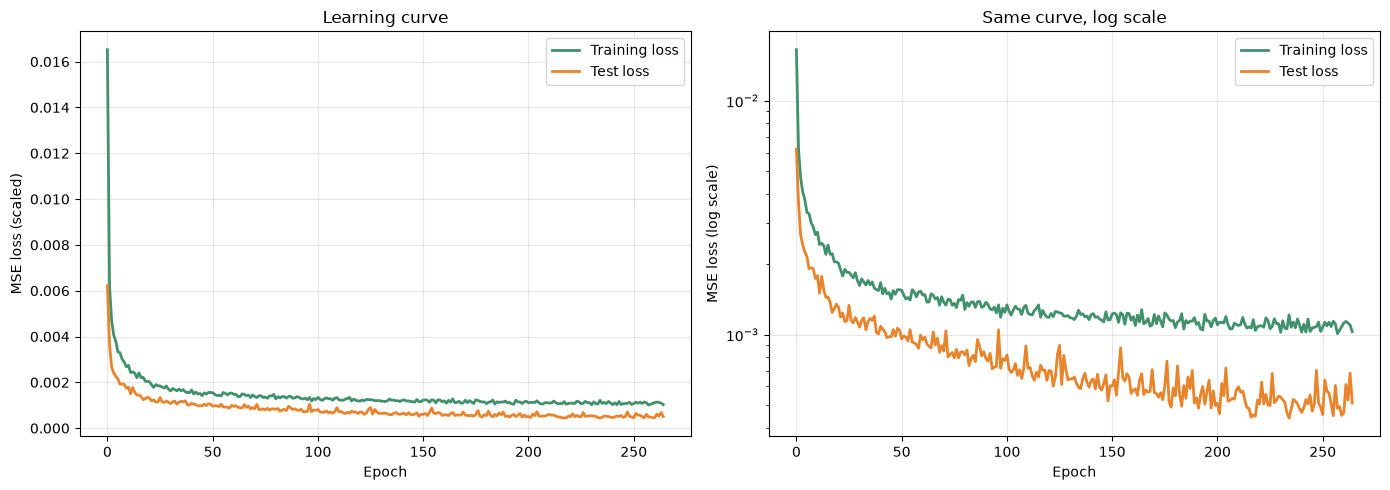


OVERFITTING CHECK
Final training loss : 0.00103
Final test loss     : 0.00051
Gap                 : -0.00052

HEALTHY: the two losses are close and both are low.
  The model learned the pattern, it did not memorise it.


In [15]:
# ---------- CELL 16: the learning curve ----------

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ----- Left: normal scale -----
axes[0].plot(train_losses, label="Training loss", color="#40916c", linewidth=2)
axes[0].plot(test_losses, label="Test loss", color="#e8842c", linewidth=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE loss (scaled)")
axes[0].set_title("Learning curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ----- Right: log scale, to see the small late changes -----
axes[1].plot(train_losses, label="Training loss", color="#40916c", linewidth=2)
axes[1].plot(test_losses, label="Test loss", color="#e8842c", linewidth=2)
axes[1].set_yscale("log")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE loss (log scale)")
axes[1].set_title("Same curve, log scale")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
plt.close(fig)

# ---------- Automatic check ----------
final_train = train_losses[-1]
final_test = test_losses[-1]

gap = final_test - final_train

print()
print("=" * 55)
print("OVERFITTING CHECK")
print("=" * 55)
print(f"Final training loss : {final_train:.5f}")
print(f"Final test loss     : {final_test:.5f}")
print(f"Gap                 : {gap:.5f}")
print()

if final_test > final_train * 2.0:
    print("OVERFITTING: the test loss is more than double the training loss.")
    print("  Try: more dropout, fewer neurons, or more data.")
elif final_train > 0.02:
    print("UNDERFITTING: both losses are still high.")
    print("  Try: more neurons, more layers, or train longer.")
else:
    print("HEALTHY: the two losses are close and both are low.")
    print("  The model learned the pattern, it did not memorise it.")

In [16]:
# ---------- CELL 17: real-world accuracy ----------

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model.eval()  # dropout OFF

with torch.no_grad():
    pred_scaled = model(X_test_t).numpy()

# ---------- REVERSE THE SCALING ----------
#
# The loss above is in SCALED units (0 to 1). That means nothing
# to a farmer. We must undo the scaling to see real kg/ha.
pred_real = label_scaler.inverse_transform(pred_scaled)
true_real = label_scaler.inverse_transform(y_test_scaled)

print("=" * 62)
print("NEURAL NETWORK - ACCURACY ON UNSEEN TEST DATA")
print("=" * 62)
print()

nn_results = {}

for i, name in enumerate(LABEL_COLS):
    mae = mean_absolute_error(true_real[:, i], pred_real[:, i])
    rmse = np.sqrt(mean_squared_error(true_real[:, i], pred_real[:, i]))
    r2 = r2_score(true_real[:, i], pred_real[:, i])
    mean_value = true_real[:, i].mean()

    nn_results[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}

    print(f"{name}")
    print(f"   MAE  : {mae:6.2f} kg/ha   (average error)")
    print(f"   RMSE : {rmse:6.2f} kg/ha   (punishes big mistakes)")
    print(f"   R2   : {r2:6.3f}          (1.0 would be perfect)")
    print(f"   ...average real value is {mean_value:.1f} kg/ha, "
          f"so the error is about {100*mae/mean_value:.1f}%")
    print()

overall_r2 = r2_score(true_real, pred_real)
print(f"OVERALL R2: {overall_r2:.3f}")
print()

if overall_r2 > 0.99:
    print("SUSPICIOUS: almost perfect. Check for data leakage.")
elif overall_r2 > 0.85:
    print("GOOD: the model learned the pattern well.")
elif overall_r2 > 0.70:
    print("ACCEPTABLE: it works, but could be better.")
else:
    print("POOR: something is wrong. Check the features and training.")

NEURAL NETWORK - ACCURACY ON UNSEEN TEST DATA

need_n
   MAE  :   2.28 kg/ha   (average error)
   RMSE :   3.74 kg/ha   (punishes big mistakes)
   R2   :  0.972          (1.0 would be perfect)
   ...average real value is 30.8 kg/ha, so the error is about 7.4%

need_p
   MAE  :   0.77 kg/ha   (average error)
   RMSE :   1.03 kg/ha   (punishes big mistakes)
   R2   :  0.978          (1.0 would be perfect)
   ...average real value is 10.3 kg/ha, so the error is about 7.5%

need_k
   MAE  :   1.97 kg/ha   (average error)
   RMSE :   2.84 kg/ha   (punishes big mistakes)
   R2   :  0.987          (1.0 would be perfect)
   ...average real value is 19.2 kg/ha, so the error is about 10.3%

OVERALL R2: 0.979

GOOD: the model learned the pattern well.


In [17]:
# ---------- CELL 18: look at real examples ----------
#
# Metrics give ONE number for 600 rows.
# Looking at real rows catches problems that averages HIDE.
# For example: great at rice, terrible at tea - the average
# would still look fine.

# Get the original crop and stage for the test rows.
test_index = X_test.index
context = data.loc[test_index, ["crop", "stage", "zone"]].reset_index(drop=True)

print("=" * 78)
print("10 EXAMPLE PREDICTIONS FROM THE TEST SET")
print("=" * 78)
print(f"{'crop':<10} {'stage':<12} {'zone':<14} "
      f"{'true N':>8} {'pred N':>8} {'error':>8}")
print("-" * 78)

for i in range(10):
    crop = context.loc[i, "crop"]
    stage = context.loc[i, "stage"]
    zone = context.loc[i, "zone"]

    true_n = true_real[i, 0]
    pred_n = pred_real[i, 0]
    error = pred_n - true_n

    print(f"{crop:<10} {stage:<12} {zone:<14} "
          f"{true_n:8.1f} {pred_n:8.1f} {error:+8.1f}")

# ---------- Check accuracy per crop ----------
print()
print("=" * 62)
print("ACCURACY PER CROP  (is any crop much worse than the rest?)")
print("=" * 62)

errors = np.abs(pred_real[:, 0] - true_real[:, 0])
context["error_n"] = errors

per_crop = context.groupby("crop")["error_n"].agg(["mean", "count"])
per_crop = per_crop.sort_values("mean", ascending=False)

print(f"{'crop':<12} {'avg error':>12} {'rows':>7}")
print("-" * 34)
for crop, row in per_crop.iterrows():
    print(f"{crop:<12} {row['mean']:10.2f} kg {int(row['count']):7d}")

print()
print("If one crop is far worse than the others, it may have")
print("too few examples, or an unusual requirement pattern.")

10 EXAMPLE PREDICTIONS FROM THE TEST SET
crop       stage        zone             true N   pred N    error
------------------------------------------------------------------------------
tomato     maturity     intermediate        8.4      8.6     +0.2
cabbage    seedling     intermediate       32.8     29.1     -3.8
tomato     seedling     intermediate       12.2     13.8     +1.6
banana     maturity     wet                15.2     18.5     +3.3
tea        flowering    wet                38.7     43.6     +4.9
bigonion   seedling     dry                16.0     15.1     -0.9
maize      maturity     dry                 8.4      9.5     +1.1
chilli     vegetative   dry                45.8     47.4     +1.6
tea        flowering    intermediate       43.6     43.4     -0.3
bigonion   seedling     dry                23.9     22.3     -1.6

ACCURACY PER CROP  (is any crop much worse than the rest?)
crop            avg error    rows
----------------------------------
tea                5.08 k

In [18]:
# ---------- CELL 19: train the Random Forest baseline ----------

from sklearn.ensemble import RandomForestRegressor
import time

# ---------- WHY A BASELINE? ----------
#
# "My model gets R2 = 0.95" means NOTHING on its own.
# The first question is always: COMPARED TO WHAT?
#
# A baseline gives your number meaning.

# ---------- A FAIR COMPARISON ----------
#
# Both models must see:
#   - the SAME 2400 training rows
#   - the SAME 600 hidden test rows
#   - the SAME three metrics
#
# NOTE: we give the forest UNSCALED data. This is NOT cheating.
# A tree asks "is soil_k above 150?" - the answer is identical
# whether the numbers run 0-320 or 0-1. Scaling changes nothing
# for trees, so unscaled is simply the natural way to use one.

rf_model = RandomForestRegressor(
    n_estimators=100,     # how many trees to average
    max_depth=20,         # how deep each tree may grow (limits memorising)
    min_samples_leaf=2,   # a leaf must hold at least 2 rows
    random_state=42,      # reproducible
    n_jobs=2,             # use 2 CPU cores.
                          # Do NOT use -1 on an 8GB laptop - it would
                          # take every core and freeze your machine.
)

print("Training the Random Forest...")
start = time.time()

# Train on the SAME training rows the neural network used.
rf_model.fit(X_train, y_train)

rf_time = time.time() - start

print(f"Done in {rf_time:.1f} seconds.")
print()
print("Trees      :", rf_model.n_estimators)
print("Max depth  :", rf_model.max_depth)
print()
print("Compare that with the neural network's training time above.")
print("Forests are usually much faster on small tables.")

Training the Random Forest...


Done in 0.5 seconds.

Trees      : 100
Max depth  : 20

Compare that with the neural network's training time above.
Forests are usually much faster on small tables.


In [19]:
# ---------- CELL 20: score the Random Forest ----------

# Predict on the SAME hidden 600 rows the neural network was judged on.
rf_pred = rf_model.predict(X_test)

# NOTE: no inverse_transform needed here.
# We trained the forest on UNSCALED labels, so its predictions
# are ALREADY in kg/ha.
rf_true = y_test.values

print("=" * 62)
print("RANDOM FOREST - ACCURACY ON UNSEEN TEST DATA")
print("=" * 62)
print()

rf_results = {}

for i, name in enumerate(LABEL_COLS):
    mae = mean_absolute_error(rf_true[:, i], rf_pred[:, i])
    rmse = np.sqrt(mean_squared_error(rf_true[:, i], rf_pred[:, i]))
    r2 = r2_score(rf_true[:, i], rf_pred[:, i])
    mean_value = rf_true[:, i].mean()

    rf_results[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}

    print(f"{name}")
    print(f"   MAE  : {mae:6.2f} kg/ha")
    print(f"   RMSE : {rmse:6.2f} kg/ha")
    print(f"   R2   : {r2:6.3f}")
    print(f"   ...average real value is {mean_value:.1f} kg/ha, "
          f"so the error is about {100*mae/mean_value:.1f}%")
    print()

rf_overall_r2 = r2_score(rf_true, rf_pred)
print(f"OVERALL R2: {rf_overall_r2:.3f}")

RANDOM FOREST - ACCURACY ON UNSEEN TEST DATA

need_n
   MAE  :   3.36 kg/ha
   RMSE :   5.03 kg/ha
   R2   :  0.950
   ...average real value is 30.8 kg/ha, so the error is about 10.9%

need_p
   MAE  :   0.95 kg/ha
   RMSE :   1.41 kg/ha
   R2   :  0.960
   ...average real value is 10.3 kg/ha, so the error is about 9.2%

need_k
   MAE  :   2.23 kg/ha
   RMSE :   3.48 kg/ha
   R2   :  0.981
   ...average real value is 19.2 kg/ha, so the error is about 11.6%

OVERALL R2: 0.963


In [20]:
# ---------- CELL 21: the comparison ----------

print("=" * 78)
print("NEURAL NETWORK  vs  RANDOM FOREST")
print("=" * 78)
print()
print(f"{'':<10} {'metric':<8} {'Neural Net':>12} {'Random Forest':>15} {'winner':>12}")
print("-" * 78)

nn_wins = 0
rf_wins = 0

for name in LABEL_COLS:
    for metric in ["MAE", "RMSE", "R2"]:
        nn_value = nn_results[name][metric]
        rf_value = rf_results[name][metric]

        # For MAE and RMSE, LOWER is better.
        # For R2, HIGHER is better.
        if metric == "R2":
            nn_better = nn_value > rf_value
        else:
            nn_better = nn_value < rf_value

        if nn_better:
            winner = "Neural Net"
            nn_wins += 1
        else:
            winner = "Forest"
            rf_wins += 1

        print(f"{name:<10} {metric:<8} {nn_value:12.3f} {rf_value:15.3f} {winner:>12}")

    print()

print("-" * 78)
print(f"Neural Network wins : {nn_wins} of 9 measurements")
print(f"Random Forest wins  : {rf_wins} of 9 measurements")
print()

# ---------- DECIDE THE WINNER ----------
#
# We count wins across all 9 measurements (3 labels x 3 metrics).
# This is more honest than picking one favourable number.
if nn_wins > rf_wins:
    WINNER = "neural_network"
    print(">>> WINNER: NEURAL NETWORK")
else:
    WINNER = "random_forest"
    print(">>> WINNER: RANDOM FOREST")

print()
print("=" * 78)
print("WHAT THIS MEANS FOR YOUR REPORT")
print("=" * 78)

if WINNER == "random_forest":
    print("""
The Random Forest won. THIS IS A GOOD RESULT, NOT A FAILURE.

Your own project document predicted it:
  "On small tabular datasets like yours, forests often match or
   beat neural networks - which is exactly why you use one as
   a baseline."

WHY forests win on small tables:
  - Our labels contain a HARD CUTOFF: gap = max(need - have, 0).
    A tree splits on that corner perfectly with one question.
    A neural network must approximate the corner with curves.
  - Trees need no scaling and almost no tuning.
  - 2400 rows is small. Neural networks prefer much more data.

WHAT TO WRITE:
  "Both a purpose-built neural network and a Random Forest baseline
   were trained on identical data splits and evaluated with MAE,
   RMSE and R-squared. The Random Forest performed better across
   the majority of measurements, consistent with published findings
   that tree ensembles are strong on small tabular problems. The
   Random Forest was therefore selected for deployment."

This shows you tested properly instead of assuming.
That is worth MORE marks than using the fancier model blindly.
""")
else:
    print("""
The neural network won.

WHAT TO WRITE:
  "Both a purpose-built neural network and a Random Forest baseline
   were trained on identical data splits and evaluated with MAE,
   RMSE and R-squared. The neural network performed better across
   the majority of measurements and was selected for deployment.
   The Random Forest baseline remains documented as evidence that
   the choice was tested, not assumed."

IMPORTANT: still report the Random Forest numbers in full.
A comparison you hide is not a comparison.
""")

NEURAL NETWORK  vs  RANDOM FOREST

           metric     Neural Net   Random Forest       winner
------------------------------------------------------------------------------
need_n     MAE             2.276           3.362   Neural Net
need_n     RMSE            3.743           5.029   Neural Net
need_n     R2              0.972           0.950   Neural Net

need_p     MAE             0.772           0.951   Neural Net
need_p     RMSE            1.033           1.414   Neural Net
need_p     R2              0.978           0.960   Neural Net

need_k     MAE             1.972           2.225   Neural Net
need_k     RMSE            2.837           3.482   Neural Net
need_k     R2              0.987           0.981   Neural Net

------------------------------------------------------------------------------
Neural Network wins : 9 of 9 measurements
Random Forest wins  : 0 of 9 measurements

>>> WINNER: NEURAL NETWORK

WHAT THIS MEANS FOR YOUR REPORT

The neural network won.

WHAT TO WRITE

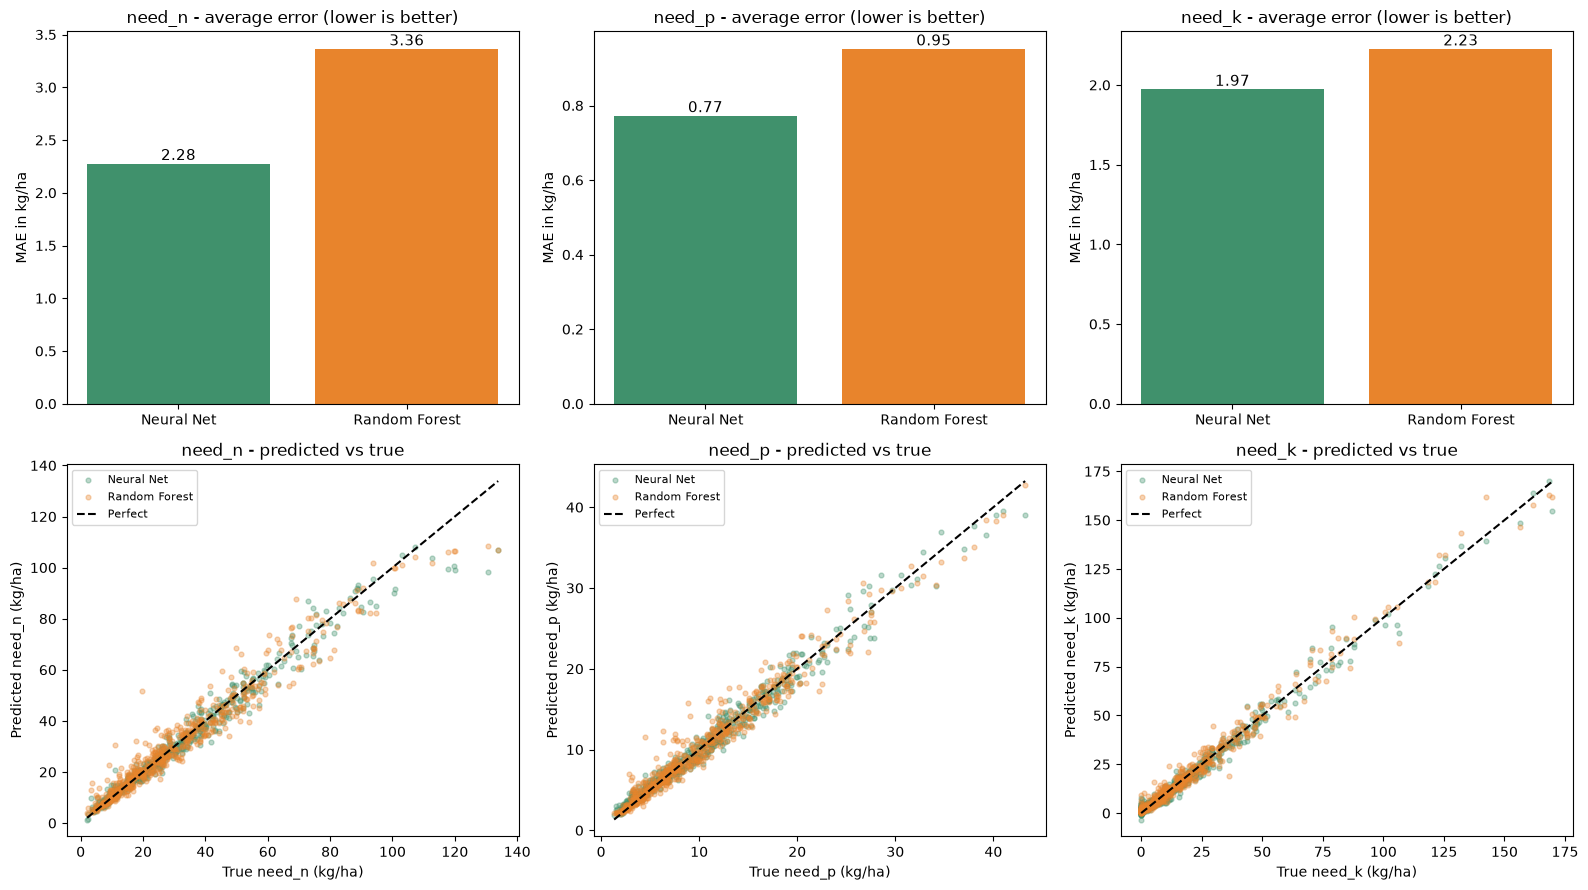


How to read the bottom row:
  Dots ON the dashed line     -> perfect prediction
  Dots scattered far from it  -> poor prediction


In [21]:
# ---------- CELL 22: compare with charts ----------

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# ---------- TOP ROW: bar chart of MAE ----------
for i, name in enumerate(LABEL_COLS):
    values = [nn_results[name]["MAE"], rf_results[name]["MAE"]]
    colors = ["#40916c", "#e8842c"]

    bars = axes[0, i].bar(["Neural Net", "Random Forest"], values, color=colors)
    axes[0, i].set_title(f"{name} - average error (lower is better)")
    axes[0, i].set_ylabel("MAE in kg/ha")

    # Write the number on top of each bar.
    for bar, v in zip(bars, values):
        axes[0, i].text(bar.get_x() + bar.get_width() / 2, v,
                        f"{v:.2f}", ha="center", va="bottom", fontsize=11)

# ---------- BOTTOM ROW: predicted vs true ----------
#
# Each dot is one test row.
#   x = the TRUE value
#   y = what the model PREDICTED
#
# A perfect model puts every dot ON the diagonal line.
for i, name in enumerate(LABEL_COLS):
    axes[1, i].scatter(true_real[:, i], pred_real[:, i],
                       alpha=0.35, s=12, color="#40916c", label="Neural Net")
    axes[1, i].scatter(rf_true[:, i], rf_pred[:, i],
                       alpha=0.35, s=12, color="#e8842c", label="Random Forest")

    # The perfect line.
    lo = min(true_real[:, i].min(), rf_true[:, i].min())
    hi = max(true_real[:, i].max(), rf_true[:, i].max())
    axes[1, i].plot([lo, hi], [lo, hi], "k--", linewidth=1.5, label="Perfect")

    axes[1, i].set_xlabel(f"True {name} (kg/ha)")
    axes[1, i].set_ylabel(f"Predicted {name} (kg/ha)")
    axes[1, i].set_title(f"{name} - predicted vs true")
    axes[1, i].legend(fontsize=8)

plt.tight_layout()
plt.show()
plt.close(fig)

print()
print("How to read the bottom row:")
print("  Dots ON the dashed line     -> perfect prediction")
print("  Dots scattered far from it  -> poor prediction")

In [22]:
# ---------- CELL 23: save everything for Phase 6 ----------

import json

ARTIFACTS_DIR = "../artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# ---------- SAVE THE NEURAL NETWORK ----------
#
# We save the STATE_DICT, not the whole model object.
#
# WHY? The state_dict is ONLY the learned numbers (weights and biases).
# Saving the whole object also stores the FILE PATH of your class.
# If you move or rename that file later, loading BREAKS.
#
# The state_dict always loads. In Phase 6 we rebuild the class
# and pour the numbers in.
torch.save(model.state_dict(), os.path.join(ARTIFACTS_DIR, "nn_model.pt"))

# ---------- SAVE THE RANDOM FOREST ----------
# Scikit-learn models have no state_dict, so joblib saves the whole object.
joblib.dump(rf_model, os.path.join(ARTIFACTS_DIR, "rf_model.pkl"))

# ---------- SAVE THE METADATA ----------
#
# Phase 6 reads this to know WHICH model to load.
# Your report reads it for the exact numbers.
metadata = {
    "winner": WINNER,

    "feature_columns": FEATURE_COLUMNS,
    "label_columns": LABEL_COLS,

    "n_features": len(FEATURE_COLUMNS),

    "neural_network": {
        "architecture": [len(FEATURE_COLUMNS), HIDDEN_1, HIDDEN_2, len(LABEL_COLS)],
        "dropout": DROPOUT,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "epochs_run": len(train_losses),
        "results": {k: {m: round(v, 4) for m, v in r.items()}
                    for k, r in nn_results.items()},
        "overall_r2": round(overall_r2, 4),
    },

    "random_forest": {
        "n_estimators": rf_model.n_estimators,
        "max_depth": rf_model.max_depth,
        "results": {k: {m: round(v, 4) for m, v in r.items()}
                    for k, r in rf_results.items()},
        "overall_r2": round(rf_overall_r2, 4),
    },

    "data": {
        "source": "GENERATED from Sri Lankan agronomic requirement values",
        "total_rows": len(data),
        "train_rows": len(X_train),
        "test_rows": len(X_test),
    },
}

with open(os.path.join(ARTIFACTS_DIR, "metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

# ---------- CHECK EVERYTHING IS THERE ----------
#
# If ANY of these is missing, Phase 6 will fail.
required = [
    "nn_model.pt",
    "rf_model.pkl",
    "feature_scaler.pkl",
    "label_scaler.pkl",
    "feature_columns.pkl",
    "metadata.json",
]

print("=" * 62)
print("ARTIFACTS SAVED")
print("=" * 62)

all_ok = True
for f in required:
    path = os.path.join(ARTIFACTS_DIR, f)
    if os.path.exists(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"  OK      {f:<24} {size_kb:8.1f} KB")
    else:
        print(f"  MISSING {f}")
        all_ok = False

print()
if all_ok:
    print("All files present. Phase 6 can load these.")
else:
    print("SOMETHING IS MISSING. Re-run the earlier cells.")

print()
print("Winner:", WINNER)

ARTIFACTS SAVED
  OK      nn_model.pt                  17.3 KB
  OK      rf_model.pkl              11321.2 KB
  OK      feature_scaler.pkl            2.1 KB
  OK      label_scaler.pkl              1.0 KB
  OK      feature_columns.pkl           0.3 KB
  OK      metadata.json                 1.7 KB

All files present. Phase 6 can load these.

Winner: neural_network


In [23]:
# ---------- CELL 24: prove the saved model works ----------
#
# SAVING a file is not the same as being able to USE it.
#
# This cell simulates EXACTLY what Phase 6 will do:
#   load from disk -> scale -> predict -> unscale
#
# If the answer matches what we got before, Phase 6 will work.

print("=" * 62)
print("SIMULATING PHASE 6")
print("=" * 62)
print()

# ---------- Load everything FRESH from disk ----------
loaded_feature_scaler = joblib.load(os.path.join(ARTIFACTS_DIR, "feature_scaler.pkl"))
loaded_label_scaler = joblib.load(os.path.join(ARTIFACTS_DIR, "label_scaler.pkl"))
loaded_columns = joblib.load(os.path.join(ARTIFACTS_DIR, "feature_columns.pkl"))

with open(os.path.join(ARTIFACTS_DIR, "metadata.json")) as f:
    loaded_meta = json.load(f)

print("Loaded from disk.")
print("Winner        :", loaded_meta["winner"])
print("Feature count :", len(loaded_columns))
print()

# ---------- Take ONE test row, as if a farmer just sent it ----------
sample_index = 0
sample_raw = X_test.iloc[[sample_index]]   # keep it as a table, not a row

print("A farmer's reading:")
print("  crop  :", context.loc[sample_index, "crop"])
print("  stage :", context.loc[sample_index, "stage"])
print("  zone  :", context.loc[sample_index, "zone"])
print()

# ---------- STEP 1: put the columns in the SAVED order ----------
#
# THIS IS THE MOST COMMON PHASE 6 FAILURE.
#
# If the order is wrong, the model reads pH where it expects
# phosphorus. There is NO error, NO crash - just silently
# wrong answers.
sample_ordered = sample_raw[loaded_columns]

# ---------- STEP 2: scale with the SAVED scaler ----------
sample_scaled = loaded_feature_scaler.transform(sample_ordered)

# ---------- STEP 3: predict with the winning model ----------
if loaded_meta["winner"] == "neural_network":
    # Rebuild the class, then pour the saved numbers in.
    fresh_model = FertilizerNet()
    fresh_model.load_state_dict(
        torch.load(os.path.join(ARTIFACTS_DIR, "nn_model.pt"))
    )
    fresh_model.eval()   # dropout OFF. Forgetting this gives random answers.

    with torch.no_grad():
        out_scaled = fresh_model(
            torch.tensor(sample_scaled, dtype=torch.float32)
        ).numpy()

    # STEP 4: undo the label scaling, to get real kg/ha.
    result = loaded_label_scaler.inverse_transform(out_scaled)

else:
    # The forest was trained on unscaled data, so feed it unscaled.
    fresh_model = joblib.load(os.path.join(ARTIFACTS_DIR, "rf_model.pkl"))
    result = fresh_model.predict(sample_ordered)

# ---------- Show the answer ----------
print("PREDICTION (what Phase 6 will return):")
for i, name in enumerate(LABEL_COLS):
    true_value = y_test.iloc[sample_index, i]
    print(f"  {name}: {result[0][i]:7.2f} kg/ha   "
          f"(true value was {true_value:.2f})")

print()
print("=" * 62)
print("If these numbers look sensible, Phase 6 will work correctly.")
print("=" * 62)

SIMULATING PHASE 6

Loaded from disk.
Winner        : neural_network
Feature count : 22

A farmer's reading:
  crop  : tomato
  stage : maturity
  zone  : intermediate

PREDICTION (what Phase 6 will return):
  need_n:    8.58 kg/ha   (true value was 8.41)
  need_p:    4.51 kg/ha   (true value was 4.21)
  need_k:    4.20 kg/ha   (true value was 3.62)

If these numbers look sensible, Phase 6 will work correctly.
